# Data Descriptive of YouNiverse

In [22]:
# Importing Libraries

from src.data.loader import load_all_raw_datasets, iterate_parquet_stream
from src.data.quality_check import check_data_quality_on_datasets
from src.utils.paths import DATASET_CHANNELS, PROCESSED_DATA_DIR, DATASET_TIMESERIES, DATASET_VIDEO_LIGHT
from src.utils.plots import *
# Code for running the pipeline
from src.data.preprocessing_new import apply_data_processing
from src.utils.general_utils import weighted_percentiles

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set seaborn style and color palette
sns.set_palette("husl")
sns.set_style("whitegrid")

# Random seed to make the code reproducible
seed=6

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Data Exploration


Our Project will need data from these datasets:
- `df_channels.tsv.gz`: Channel data.
- `df_timeseries.tsv.gz` : Channel data over time including `delta views`, `delta_videos` and `delta_subs`.
- `yt_metadata_en.jsonl.gz` : Metadata for each video
- `num_comments.tsv.gz` : Number of comments per video.
- `yt_metadata_helper.feather` : A lighter version of video metadata not including description, titles and tags.

Before proceeding please make sure these `data/raw` folder.

To get a better feel for the datasets, we begin by inspecting each of the datasets.
Our goal in this section is to understand structure, size and feasibility of working with the raw data.

### I. Loading Raw Data

Because loading all the data at the same time is not possible in a 16GB local machine, for our initial data exploration, we load a subset of a maximum 1 million rows per dataset.

In [3]:
subset_size = 1_000_000
channels_df, videos_df, videos_light_df, timeseries_df, num_comments_df = load_all_raw_datasets(nrows=subset_size)

### II. Checking data quality

Before deciding on pre-processing the data, it is important to take a look at the quality metrics.

In [4]:
df_list = [channels_df,
           videos_df,
           videos_light_df,
           timeseries_df,
           num_comments_df]

names = ["Channels", "Videos", "Videos (Light)", "Timeseries", "Num Comments"]

check_data_quality_on_datasets(df_list, names)

,Dataset,Rows,Columns,Missing %,Duplicate %,Memory (MB),Numeric Cols,Categorical Cols,Non-Null % (avg),Unique % (avg),Min Numeric,Max Numeric
1,Videos,1000000,8,0.49,0.0,222.04,4,4,99.51,15.34,0.0000,1.101396e+09
3,Timeseries,1000000,10,0.01,0.0,244.81,7,3,99.99,32.20,0.0000,1.334730e+10
2,Videos (Light),1000000,12,0.33,0.0,2382.38,4,8,99.67,38.61,0.0000,1.101396e+09
4,Num Comments,1000000,2,0.00,0.0,64.85,1,1,100.00,50.40,0.0000,2.231960e+05
0,Channels,136470,8,0.01,0.0,37.25,4,4,99.99,42.90,2.0865,1.121395e+08


The quick quality report tells us there are not a lot of missing values. However, we should be aware of that and preprocess the data.

### III. Correlation matrix

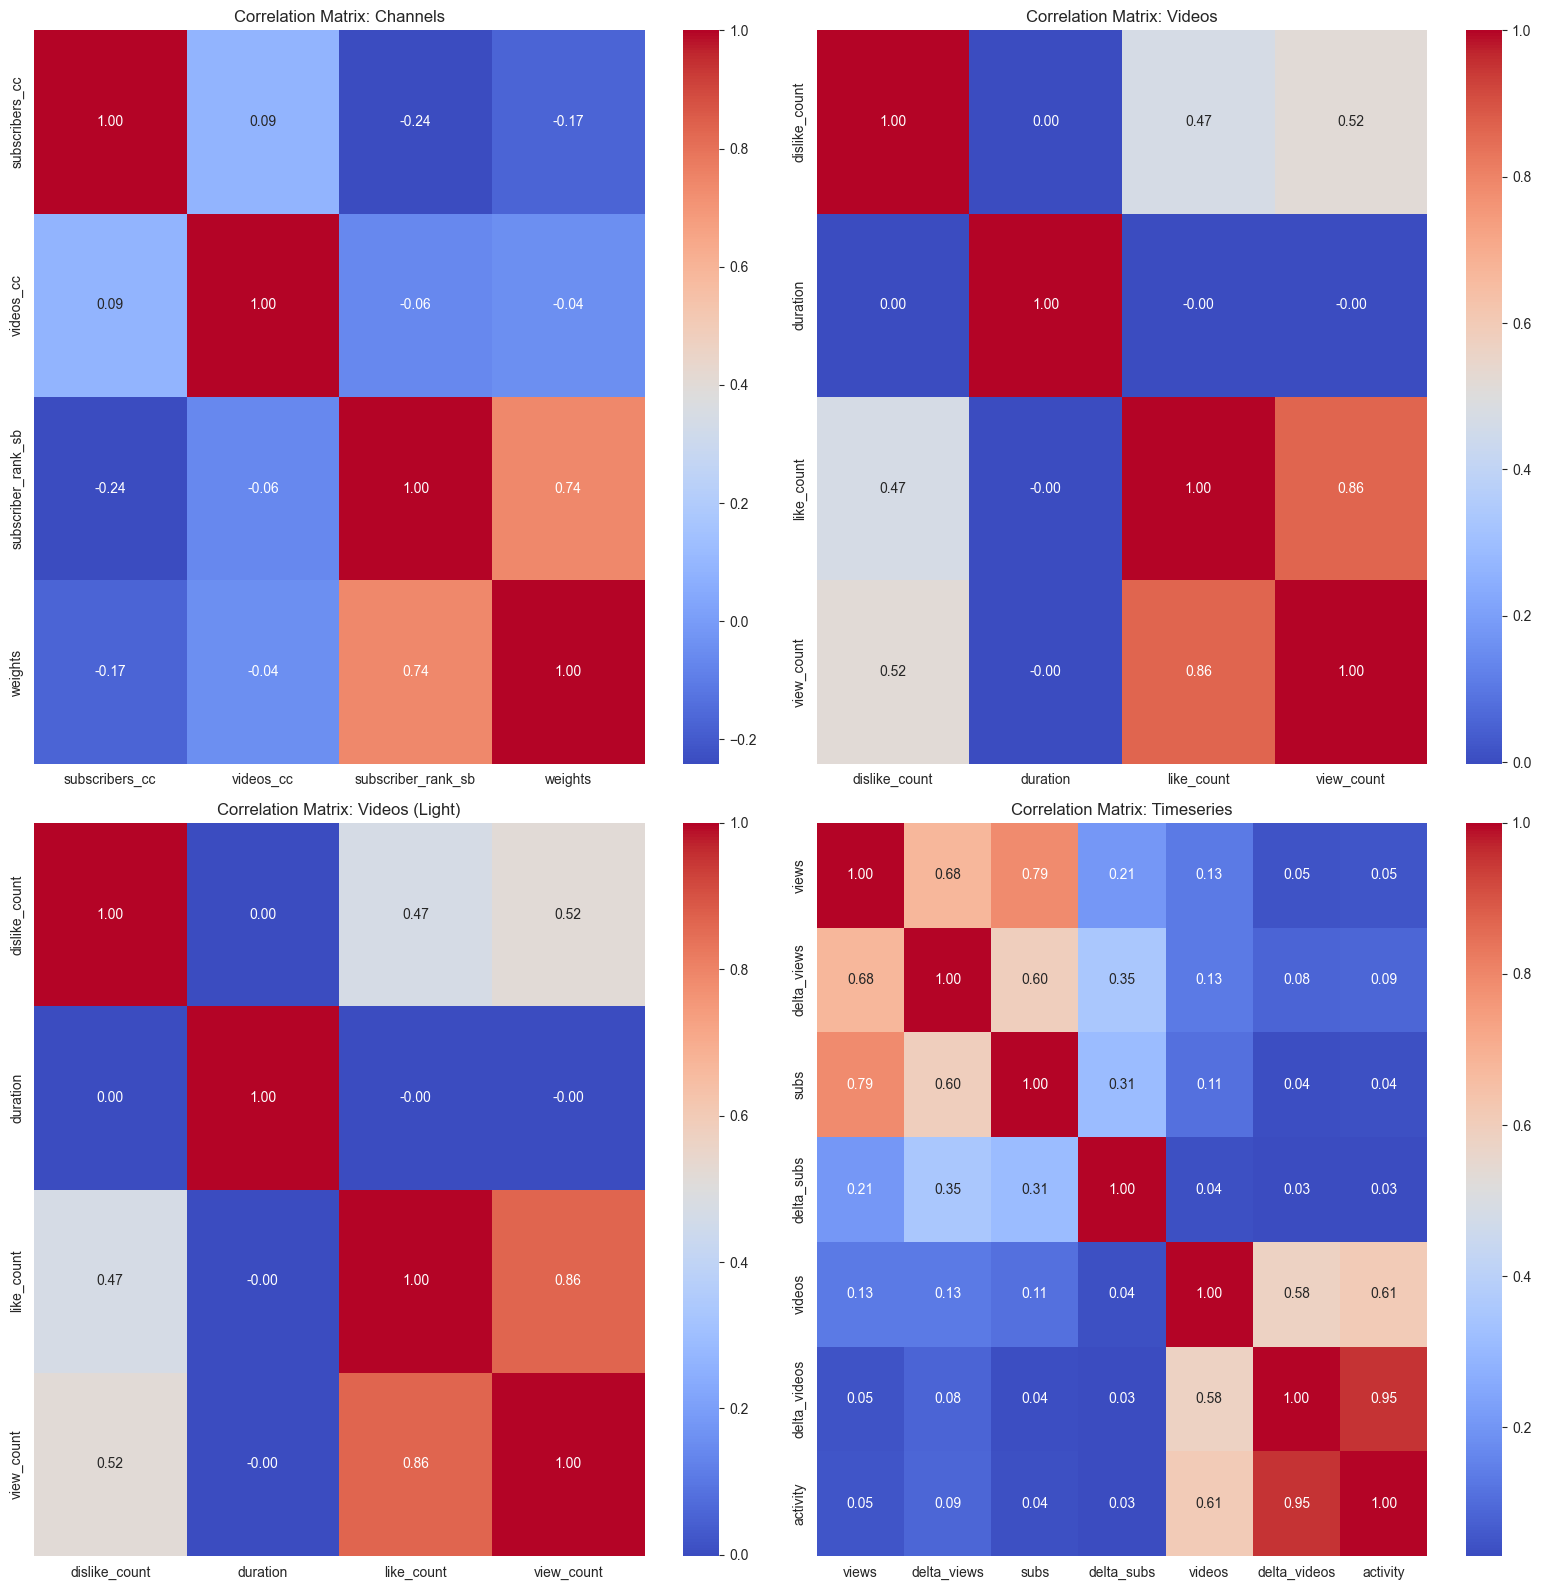

In [8]:
# Filter out the 'Num Comments' dataframe
filtered_df_list = [df for df, name in zip(
    df_list, names) if name != "Num Comments"]
filtered_names = [name for name in names if name != "Num Comments"]

fig = plot_correlation_matrices(filtered_df_list, filtered_names)
plt.show()


First glance insights:
- Channel-level correlations are weak, more uploads don’t clearly relate to more subscribers or better ranks.
- Video-level metrics (views, likes, dislikes) are tightly linked, while duration shows no clear impact on engagement.
- In time-series data, views and subscribers grow together but with only moderate alignment in their weekly changes.

### III. Decisions on Data Preprocessing

Because the dataset is large, we process the data and save the results in Parquet format.
This format allows for faster access and supports iterative reading, which solves the issue of not being able to load everything into memory at once.
The following steps are taken in align with the project goals, code is located in `src/data/preprocessing.py`

#### Cleaning & Storage
We perform standard cleaning for each dataset — removing duplicates, normalizing types and formats, and parsing dates.

Additionally, we created a **new lightweight dataset `tags_processed.parquet`**, containing only `channel_id`, `display_id`, `tags`, and `upload_date`.
This dataset will be used later in **Research Question 2 and 5**  to cluster different youtube categories and identifying trends, and was separated to allow **faster processing** without reloading the large video metadata file.


##### Feature Engineering
Feature engineering is a key part of our pipeline, as these variables are later reused across multiple analyses.
Bellow are some of the most important ones:

- **Engagement Efficiency (video level)**
  For each video *v*:
  $$
  E_v = \frac{\text{likes}_v + \text{dislikes}_v + \text{comments}_v}{\text{views}_v}
  $$
  This score is used for detecting outperformers, and since it is reused a lot, we decided to include it in our saved processed datasets.

<br>

In `time_series.data`, <br>
we align all events to **weekly periods (W-MON)** and aggregate per channel:
- `reactions_week = Σ(likes + dislikes + comments)`
- `views_week = Σ(views)`

We then compute:
- **Weekly Efficiency**
  $$
  E_{\text{week}} = \frac{\text{reactions\_week}}{\text{views\_week}}
  $$
- **4-Week Trailing Efficiency**
  A rolling version for smoother trends in the `timeseries` dataset.


- **Channel Aggregates (from processed videos)**
  - `avg_engagement_efficiency` — mean efficiency across all channel videos
  - `total_views`, `total_like_count`, `total_dislike_count`, `total_num_comms` — cumulative metrics
  - `avg_video_like_ratio`, `video_count_processed` — engagement and volume indicators
  - `channel_age_days`, `videos_per_day` — activity and lifespan measures

All processed datasets are saved under `/data/processed/` for efficient downstream use.

## 2. Loading the data


### I. Run the preprocessing pipeline

By running the preprocessing pipeline, it takes each dataset from the `data/raw` folder, preprocesses them and saves them in `data/processed` for later use. Before runing the function, please make sure you have the puyhton libraries in `requirements.txt` installed, and you have the original datasets in the `raw` folder.

This process might take more than 30 minutes.


In [5]:
apply_data_processing()

STEP 1: Loading existing num_comments (already processed)

STEP 2: video_light already processed, skipping
  Path: /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/videos_light_processed.parquet

STEP 3: Loading existing channels (already processed)
  Shape: (136470, 18)

STEP 4: timeseries already processed, skipping
  Path: /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/timeseries_processed.parquet

DATA PROCESSING COMPLETE!
All processed files saved to: /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed

Processed files:
  - /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/num_comments_processed.parquet
  - /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/videos_light_processed.parquet
  - /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/channels_processed.parquet
  - /Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/timeseries_proc

{'channels': '/Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/channels_processed.parquet',
 'timeseries': '/Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/timeseries_processed.parquet',
 'videos_light': '/Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/videos_light_processed.parquet',
 'num_comments': '/Users/kal3vala/Documents/EPFL/ada-2025-project-in5ight/data/processed/num_comments_processed.parquet'}

### II. Checking the processed data

In [9]:
channel_df = pd.read_parquet(DATASET_CHANNELS)
channel_df.head(6)

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,40549
5,Entertainment,2007-01-15,UCIwFjwMjI0y7PDBVEO9-bkQ,Justin Bieber,46574085,134,12.0,2.087,4668.0,0.028706,0.025269,5.886436e+08,17697.0,8815774.0,373636.0,719646.0,128


In [10]:
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)
timeseries_df.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
0,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-01,62524.500,4113.500,1466.000,0.000,29,0,1,2016-07-26,0.049820,0.049820
1,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-08,67600.250,5075.750,1508.625,42.625,30,1,2,2016-08-02,0.049374,0.049374
2,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-15,69982.000,2381.750,1530.750,22.125,31,1,2,2016-08-09,0.045413,0.045413
3,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-22,72663.125,2681.125,1558.625,27.875,32,1,2,2016-08-16,0.046415,0.046415
4,UC--24Q3_ZQeFmgJE-Um5QZQ,Travel & Events,2016-08-29,75093.000,2429.875,1591.000,32.375,33,1,2,2016-08-23,0.031169,0.031169


Datasets that are too large to fit in memory at once like `videos_metadata_processed.parquet`, `videos_light_processed.parquet` and `tags_processed.parquet`, we process iteratively, meaning, we read it by chunks. This ensures that we can use these datasets in our Research Questions and proves feasibility.

_The larger 20GB `videos_metadata_processed.parquet` takes around 30 minutes in our local machines._


In [23]:
# Example of reading from videos_light_processed.parquet with chunks
for df_chunk in iterate_parquet_stream(DATASET_VIDEO_LIGHT, window_size=20_000_000):
    print(df_chunk.shape)

(20054016, 11)
++ Chunk 000: rows 0-20,054,016 | total=20,054,016
(20054016, 11)
++ Chunk 001: rows 20,054,016-40,108,032 | total=40,108,032
(20054016, 11)
++ Chunk 002: rows 40,108,032-60,162,048 | total=60,162,048
(12762746, 11)
++ Final chunk: rows 60,162,048-EOF | rows=12,762,746


# 3. Basic information about the data

### I. Subscribers distribution

As our research is focused on working with small- to midsize-channels, it is important to understand overall image of subscribers count.

In [30]:
# Compute weighted 50th (median) and 90th percentiles of subscriber counts
channel_df =  pd.read_parquet(DATASET_CHANNELS)
cuts = weighted_percentiles(
    channel_df["subscribers_cc"],
    channel_df["weights"],
    percentiles=(50, 90)
)
print(cuts)
p50, p90 = cuts[50], cuts[90]

{50: np.float64(22200.0), 90: np.float64(160000.0)}


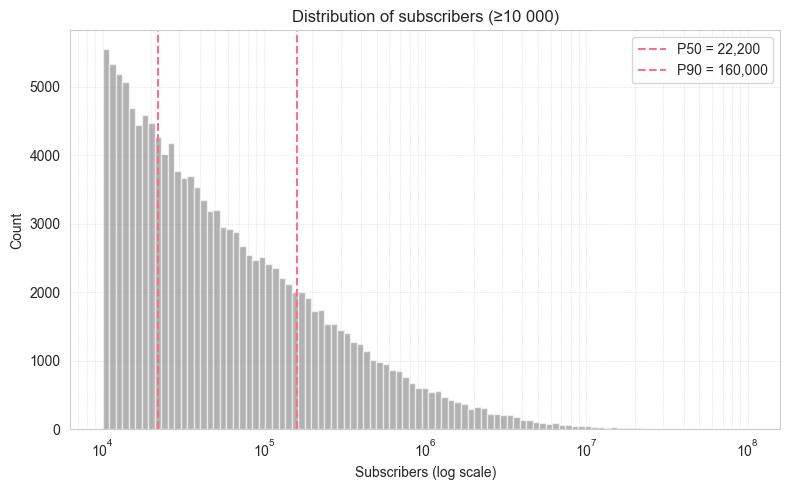

In [25]:
plot_log_histogram(
    channel_df,
    column="subscribers_cc",
    percentiles={"P50": p50, "P90": p90},
    bins=np.logspace(4, 8, 100),  # from 10^4 (10k) to 10^8
    title="Distribution of subscribers (≥10 000)",
    xlabel="Subscribers (log scale)"
)
plt.show()

The distribution is highly right-skewed (heavy-tailed), most channels cluster near the lower end (10 k – 100 k), and very few extend into the millions.

### II. to add at least something else here

# 4. Detecting Outperformers

### I. Identifying small to mid sized channels

We define our focus cohort as channels with 10 000–100 000 subscribers. The subscriber distribution is heavy-tailed: the median (P50) is ≈ 22 k and P90 is ≈ 160 k, so 100 k lies well below the top decile while meaningfully above the median. We use 100 k because it
- aligns with YouTube’s Silver Creator milestone,
- avoids dominance by a small set of very large channels and
 - provides a large, comparable sample of growing creators.

In [13]:
small_mid_sized_channels_df = channel_df[channel_df["subscribers_cc"] < 100_000].copy()

### II. Fitting the Model and Detecting the Outperformers

Outperformers are defined as small- to mid-sized channels that achieve an engagement efficiency substantially higher than what is expected for their subscriber size and category, after controlling for the heavy-tailed scaling of engagement on YouTube.

Starting from the efficiency metric that we defined in feature engineering, we continue with:

- **Expected Efficiency Model (Log–Log Linear Regression)**
  To understand how efficiency scales with channel size, we fit a log–log regression:
  $$
  \log_{10}(E_c) = a + b \, \log_{10}(\text{subscribers}_c) + \varepsilon_c
  $$
  Using logs stabilizes the heavy-tailed data and makes the relationship approximately linear.

- **Residual Efficiency (Deviation from Expectation)**
  The residual measures how much a channel over- or under-performs relative to its expected efficiency:
  $$
  r_c = \log_{10}(E_c) - \big(a + b \, \log_{10}(\text{subscribers}_c)\big)
  $$

- **Quiet Outperformers**
  Channels with residuals above a threshold \( \gamma \) (e.g., mean + 2·std or the top 5%) are labeled as outperformers:
  $$
  r_c > \gamma \;\Rightarrow\; \text{quiet outperformer}
  $$

In [14]:
from src.models.log_log_efficiency_model import linear_log_log_model

channels_model = linear_log_log_model(
    df=small_mid_sized_channels_df,
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    log_base=10,
    verbose=True,
)

channels_model.head(5)

 log–log model fitted: log(y) = -0.9058 + -0.1419 * log(x)
   Outliers (z>2.0): 719/94362 (0.76%)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_like_count,total_dislike_count,total_num_comms,video_count_processed,log_x,log_y,pred_log_y,residual,zscore,is_outlier
25085,People & Blogs,2016-07-04,UC7wnYvoFWmX-Ad6Az7BsiDQ,NinaUnrated VLOGS,98200,22,78696.0,3.6480,1210.0,0.018182,...,174949.0,2266.0,29914.0,16,4.992111,-1.164280,-1.613989,0.449709,1.233636,False
26369,Music,2018-05-13,UCCjlZHOg6TWQmJ4k3esGxCg,Kevser Öz,92300,264,83140.0,4.2195,532.0,0.496241,...,216481.0,19153.0,13512.0,267,4.965202,-1.488122,-1.610172,0.122050,0.341271,False
26531,People & Blogs,2010-09-08,UC5H8PC7IVxeicx5x5p8roWA,Casi Davis,98683,32,84226.0,4.3250,3336.0,0.009592,...,199670.0,5360.0,8565.0,35,4.994242,-1.531054,-1.614292,0.083238,0.235570,False
26730,People & Blogs,2018-05-02,UCDGY6cFaZKjlY1bguFZHdeQ,Nidal Wonder,98202,45,85347.0,4.4395,543.0,0.082873,...,299536.0,13301.0,12879.0,52,4.992120,-1.529482,-1.613991,0.084508,0.239030,False
26751,Film and Animation,2011-07-30,UC5du0zGwGLWhMAJkLmltGpg,iCraft,92800,69,85414.0,4.4265,3011.0,0.022916,...,232189.0,17840.0,2423.0,70,4.967548,-1.824856,-1.610505,-0.214352,-0.574900,False


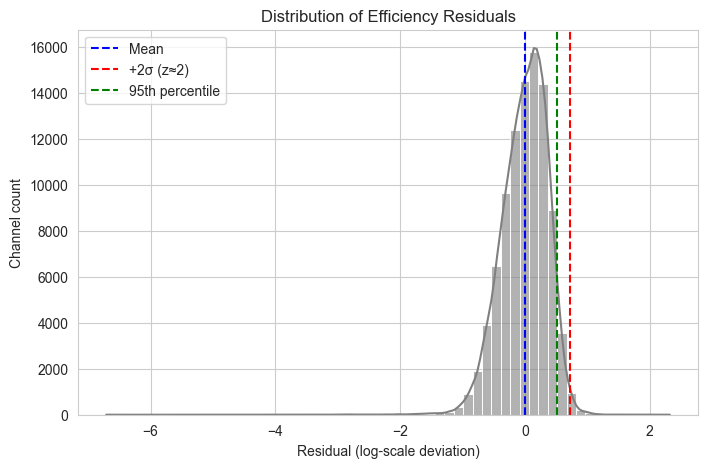

In [26]:

residuals = channels_model["residual"].dropna()
plt.figure(figsize=(8,5))
sns.histplot(residuals, bins=60, kde=True, color="gray", alpha=0.6)
plt.axvline(residuals.mean(), color="blue", linestyle="--", label="Mean")
plt.axvline(residuals.mean() + 2*residuals.std(), color="red", linestyle="--", label="+2σ (z≈2)")
plt.axvline(np.percentile(residuals, 95), color="green", linestyle="--", label="95th percentile")
plt.xlabel("Residual (log-scale deviation)")
plt.ylabel("Channel count")
plt.title("Distribution of Efficiency Residuals")
plt.legend()
plt.show()

In [37]:
gamma = np.percentile(channels_model["residual"], 97)
is_outperformer_mask = channels_model["residual"] > gamma
channel_df["is_outperformer"] = is_outperformer_mask.reindex(channel_df.index, fill_value=False)


In [38]:
outperformers_df = channel_df[channel_df['is_outperformer']]
print(len(outperformers_df))
outperformers_df.head(6)

2831


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,video_count_processed,is_outperformer
27568,Music,2012-06-17,UCGnEWsLelLFqMkWcb8s7-nA,孤独なghost,93200,121,88557.0,3.9875,2688.0,0.045015,0.105720,9817455.0,25500.0,845110.0,3881.0,10345.0,125,True
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,1086.0,0.161142,0.161395,4066492.0,68508.0,303546.0,20696.0,65870.0,181,True
30591,Gaming,2019-01-16,UCrDEwtROpcijOFP9uMwz19Q,Parallel Samzyy,79100,40,99714.0,3.7395,284.0,0.140845,0.098866,6788720.0,9521.0,604033.0,11725.0,10072.0,51,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,1411.0,0.223955,0.151517,22679099.0,91716.0,1207584.0,9496.0,104127.0,340,True
32943,Gaming,2011-09-27,UC3-8qZ-rZvlSVWwkHoeelCA,TheMythicalSausage,83000,1766,110160.0,5.0940,2952.0,0.598238,0.094543,12100847.0,3513327.0,416318.0,7942.0,87631.0,1773,True
33055,Gaming,2019-04-17,UCaH2302aYnmOJH-CWn-Bebg,Military Dave,84100,52,110730.0,4.9860,193.0,0.269430,0.110061,2810462.0,21462.0,304313.0,17771.0,30004.0,55,True


In [32]:
outperformers = channels_model[channels_model["is_outlier"]].sort_values(
    by="subscribers_cc", ascending=True)

normal_performers = channels_model[~channels_model["is_outlier"]].sort_values(
    by="subscribers_cc", ascending=True)

print(len(outperformers))
outperformers.head(10)

719


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,log_x,log_y,pred_log_y,residual,zscore,is_outlier
134651,Gaming,2018-01-10,UC01BXM3HTneoEiimOKj5j2g,SuperNova GamePro Gi...,10000,187,927075.0,21.2005,655.0,0.285496,...,742.0,25298.0,0.945329,187,4.000000,-0.446928,-1.473247,1.026319,2.804005,True
133897,Science & Technology,2012-11-14,UC-sQ0P6uSCe3vqWmzN_WSBw,DudetECH,10000,556,916328.0,16.3215,2538.0,0.219070,...,5071.0,6668.0,0.914076,569,4.000000,-0.552283,-1.473247,0.920964,2.517075,True
133454,Gaming,2016-05-22,UC-3UK-xM8oBJuYp1T0YB7Pg,Resqwad,10000,397,906030.0,14.9640,1253.0,0.316840,...,580.0,2780.0,0.950028,397,4.000000,-0.733346,-1.473247,0.739902,2.023961,True
124247,Gaming,2015-01-16,UCd2d4ljgQ1FjwQ0XNJKB1tA,Tum,10000,292,788324.0,9.8705,1745.0,0.167335,...,577.0,16169.0,0.970390,296,4.000000,-0.686213,-1.473247,0.787034,2.152323,True
133420,Gaming,2015-07-12,UCPpQnMb7d3MGYZmjFUVnuWQ,Mr. Brunswick,10000,161,905996.0,14.7320,1568.0,0.102679,...,84.0,3189.0,0.987855,164,4.000000,-0.717410,-1.473247,0.755837,2.067360,True
135238,Entertainment,2012-08-29,UCy5BM1C99Z_Xz-ozGS82xnA,Sandra's haul's,10000,707,937304.0,27.6795,2615.0,0.270363,...,4362.0,163208.0,0.973532,720,4.000000,-0.499081,-1.473247,0.974167,2.661969,True
135319,People & Blogs,2017-03-14,UCUsUGoguLcAiQGEnH9tWULA,Lil Honey,10000,108,938429.0,28.8235,957.0,0.112853,...,907.0,2024.0,0.856060,108,4.000000,-0.597489,-1.473247,0.875758,2.393960,True
136463,Entertainment,2016-11-08,UCf0RCfzyKoGr5AnLldeI1xw,On The Marc,10028,307,1007560.0,53.1435,1083.0,0.283472,...,3429.0,23050.0,0.919560,308,4.001214,-0.734033,-1.473420,0.739387,2.022559,True
134919,Entertainment,2014-01-16,UC9AaYXbH5qvbYSccHhiCWZQ,Hopping Berry Borer,10036,187,931081.0,23.4805,2110.0,0.088626,...,300.0,0.0,0.942372,186,4.001561,-0.528370,-1.473469,0.945099,2.582806,True
135688,Music,2017-11-07,UCaZjdivfF2G9Mtu4V32vbZw,skriansi music,10088,292,960435.0,53.1435,719.0,0.406120,...,13.0,1376.0,0.939209,300,4.003805,-0.728591,-1.473787,0.745196,2.038379,True


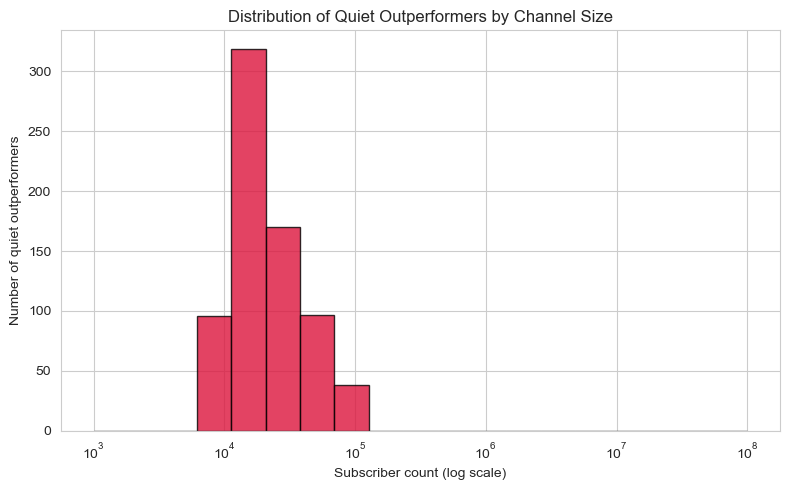

In [22]:
import matplotlib.pyplot as plt
import numpy as np


def plot_outperformer_distribution(df, subscribers_col="subscribers_cc", outperformer_col="is_outlier",
                                   bins=None, log_scale=True):
    """
    Plot the distribution of quiet outperformers across subscriber count ranges.

    X-axis: subscriber count (binned)
    Y-axis: number of outperformers in each bin
    """

    # Default: log-spaced bins from 1k to 100M subs
    if bins is None:
        bins = np.logspace(3, 8, 20)

    # Filter valid
    valid = df[df[subscribers_col] > 0]
    outp = valid[valid[outperformer_col]]

    # Histogram of outperformers
    counts, bin_edges = np.histogram(outp[subscribers_col], bins=bins)
    centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    plt.figure(figsize=(8, 5))
    plt.bar(centers, counts, width=np.diff(bin_edges), align="center",
            alpha=0.8, edgecolor="black", color="crimson")

    if log_scale:
        plt.xscale("log")

    plt.xlabel("Subscriber count (log scale)")
    plt.ylabel("Number of quiet outperformers")
    plt.title("Distribution of Quiet Outperformers by Channel Size")
    plt.tight_layout()
    plt.show()


plot_outperformer_distribution(channels_model)

#### Categories of quiet outperformers

Initially, dataset provides us a correspondance of each channel to 1 of 16 predefined categories. Let's see, how quiet outperformers are distributed by those categories and how they relate to overall distribution of categories among all channels.

_Note: those categories can be then upgraded by using some additional metadata about videos, such as tags or description data_

<Figure size 1400x600 with 0 Axes>

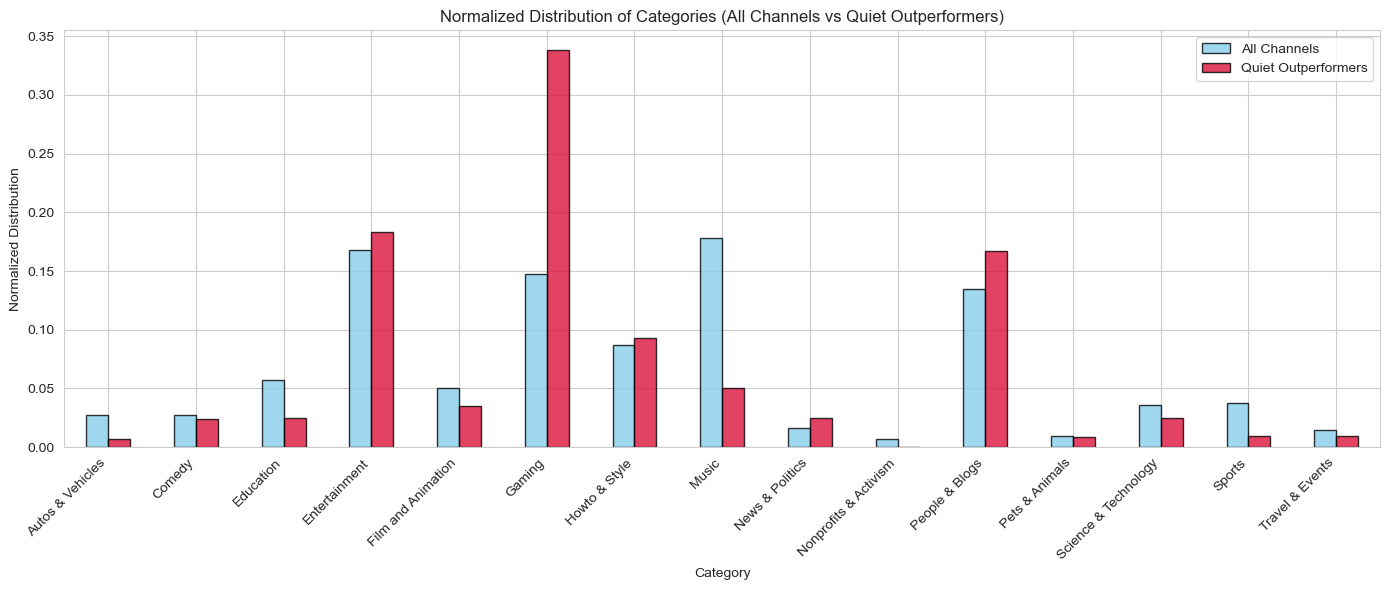

In [48]:
# Plot normalized distribution of categories for all channels and outperformers on the same plot
plt.figure(figsize=(14, 6))

# Normalize the counts to show distribution
channel_categories_norm = channel_df['category_cc'].value_counts(normalize=True)
outperformer_categories_norm = outperformers['category_cc'].value_counts(normalize=True)

# Combine both distributions into a single DataFrame for plotting
combined_df = pd.DataFrame({
    'All Channels': channel_categories_norm,
    'Quiet Outperformers': outperformer_categories_norm
}).fillna(0)  # Fill missing categories with 0

# Plot the combined normalized distributions
combined_df.plot(kind='bar', color=['skyblue', 'crimson'], edgecolor='black', alpha=0.8, figsize=(14, 6))

plt.xlabel('Category')
plt.ylabel('Normalized Distribution')
plt.title('Normalized Distribution of Categories (All Channels vs Quiet Outperformers)')
plt.xticks(rotation=45, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

Let's tak a look on one random outperformer channel

In [49]:
channel = 'UC9AaYXbH5qvbYSccHhiCWZQ'  # Example channel ID
channel_timeseries = timeseries_df[timeseries_df['channel'] == channel]

channel_timeseries.head(5)



,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,...,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
2976658,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-10-17 00:00:00,477.500000,87.500000,12.250000,0.000000,16,0,6,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186
2976659,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-10-24 00:00:00,594.500000,117.000000,15.000000,2.750000,17,1,3,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186
2976660,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-10-30 23:00:00,693.321244,98.821244,18.119171,3.119171,18,1,3,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186
2976661,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-11-06 23:00:00,807.057292,113.736048,20.489583,2.370412,19,1,2,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186
2976662,UC9AaYXbH5qvbYSccHhiCWZQ,Entertainment,2016-11-13 23:00:00,991.322531,184.265239,22.106481,1.616898,23,4,6,...,2110.0,0.088626,0.296231,53818.0,260183.0,4928.0,300.0,0.0,0.942372,186


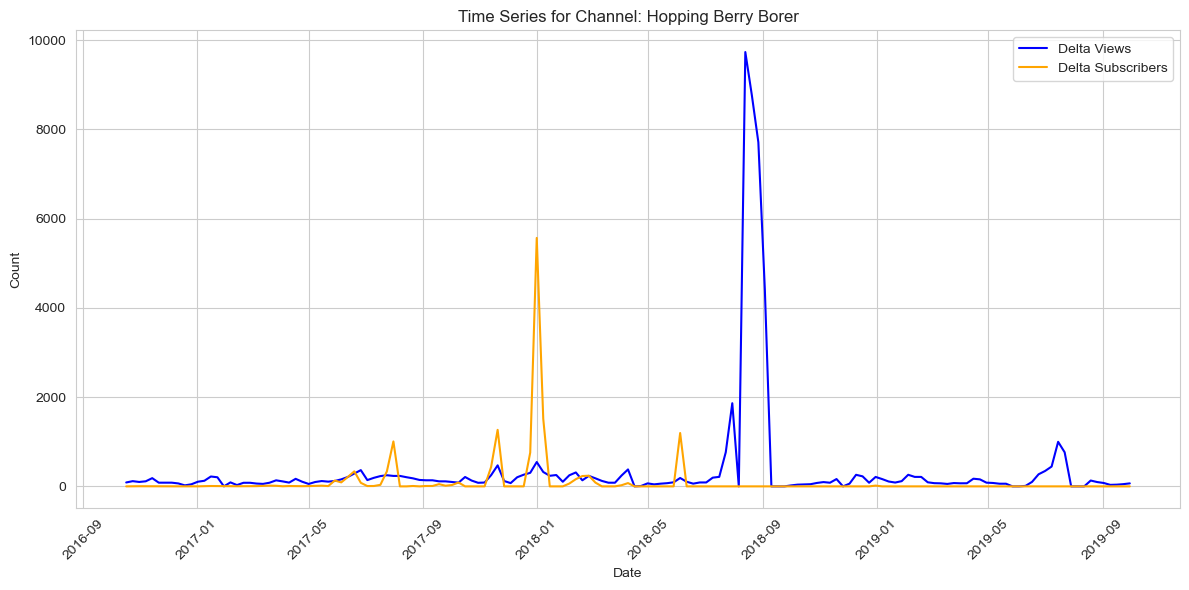

In [50]:
# plot
plt.figure(figsize=(12, 6))
plt.plot(channel_timeseries['datetime'],
         channel_timeseries['delta_views'], label='Delta Views', color='blue')
plt.plot(channel_timeseries['datetime'],
         channel_timeseries['delta_subs'], label='Delta Subscribers', color='orange')
plt.xlabel('Date')
plt.ylabel('Count')
plt.title(f'Time Series for Channel: {channel_df[channel_df["channel"] == channel]["name_cc"].values[0]}')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()